# Groupe 1 — Transplantation rénale en France
### UE Approche Transdisciplinaire — Examen 11 mai 2026

**Questions :**
1. Comment ont évolué les **dépenses pour transplantation rénale** en France ?
2. Comment a évolué la **prévalence du diabète** parmi les sujets transplantés rénaux ?

**Source :** Data Ameli — SNDS / Cnam · Période : 2015–2023  
**Outils :** Polars · Seaborn · Matplotlib

---
## 1. Imports

In [1]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Style proche de ton image
sns.set_style("whitegrid")
sns.set_context("notebook")

DATA = Path("../Data")

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(55)

print(f"Polars {pl.__version__}  |  Seaborn {sns.__version__}")

Polars 1.40.1  |  Seaborn 0.13.2


---
## 2. Chargement des fichiers CSV

In [2]:
READ_OPTS = dict(separator=";", infer_schema_length=0,
                 truncate_ragged_lines=True, encoding="utf8-lossy")

raw_dep    = pl.read_csv(DATA / "depenses.csv",     **READ_OPTS)
raw_comorb = pl.read_csv(DATA / "comorbidites.csv", **READ_OPTS)

print("depenses.csv    :", raw_dep.shape)
print("comorbidites.csv:", raw_comorb.shape)

depenses.csv    : (22320, 14)
comorbidites.csv: (40221, 16)


---
## 3. Dépenses de transplantation rénale

### 3.1 Nettoyage

In [3]:
raw_dep.glimpse()

Rows: 22320
Columns: 14
$ annee                <str> '2015', '2015', '2015', '2015', '2015', '2015', '2015', '2015', '2015', '2015'
$ patho_niv1           <str> "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes"
$ patho_niv2           <str> "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affect

In [4]:
dep = (
    raw_dep
    .with_columns([
        # Conversion des types de données
        pl.col("annee").cast(pl.Int32),
        pl.col("montant").cast(pl.Float64, strict=False),
    ])
    # Filtre sur l'insuffisance rénale chronique terminale
    .filter(pl.col("patho_niv1") == "Insuffisance rénale chronique terminale")
    # Filtre sur la transplantation rénale
    .filter(pl.col("patho_niv2") == "Transplantation rénale")
    # Filtre transplantation rénale uniquement
    .filter(pl.col("patho_niv3").is_in(["Transplantation rénale"]))
    # Filtre sur les dépenses uniquement
    .filter(pl.col("dep_niv_1")=="Dépenses")
    # Tri par année et montant
    .sort(["annee", "montant"])
)

print(f"Lignes après filtre : {dep.shape[0]}")
print(f"Années             : {sorted(dep['annee'].unique().to_list())}")
dep

Lignes après filtre : 9
Années             : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


annee,patho_niv1,patho_niv2,patho_niv3,top,dep_niv_1,dep_niv_2,montant,Ntop,N_recourant_au_poste,montant_moy,Niveau prioritaire,tri,type_somme
i32,str,str,str,str,str,str,f64,str,str,str,str,str,str
2015,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.24837042e8,"""3260""","""3260""","""68905.0""","""2,3""","""24.0""","""Total"""
2016,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.25002428e8,"""3330""","""3330""","""67609.0""","""2,3""","""24.0""","""Total"""
2017,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.37999339e8,"""3570""","""3570""","""66648.0""","""2,3""","""24.0""","""Total"""
2018,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.2408468e8,"""3330""","""3330""","""67353.0""","""2,3""","""24.0""","""Total"""
2019,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.29531901e8,"""3470""","""3470""","""66243.0""","""2,3""","""24.0""","""Total"""
2020,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",1.63567643e8,"""2510""","""2510""","""65244.0""","""2,3""","""24.0""","""Total"""
2021,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.14825226e8,"""3050""","""3050""","""70342.0""","""2,3""","""24.0""","""Total"""
2022,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.28318993e8,"""3180""","""3180""","""71708.0""","""2,3""","""24.0""","""Total"""
2023,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""Dépenses""","""Total des dépenses remboursées""",2.59676363e8,"""3360""","""3360""","""77216.0""","""2,3""","""24.0""","""Total"""


### 3.2 Figure — Évolution des dépenses totales remboursées

Chute COVID  (2019→2020) : -28.7%  (163.6 M€)
Reprise      (2020→2023) : +58.8%
Évol. totale (2015→2023) : +15.5%  (259.7 M€)


C:\Users\Abdo\AppData\Local\Temp\ipykernel_26652\2361844745.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


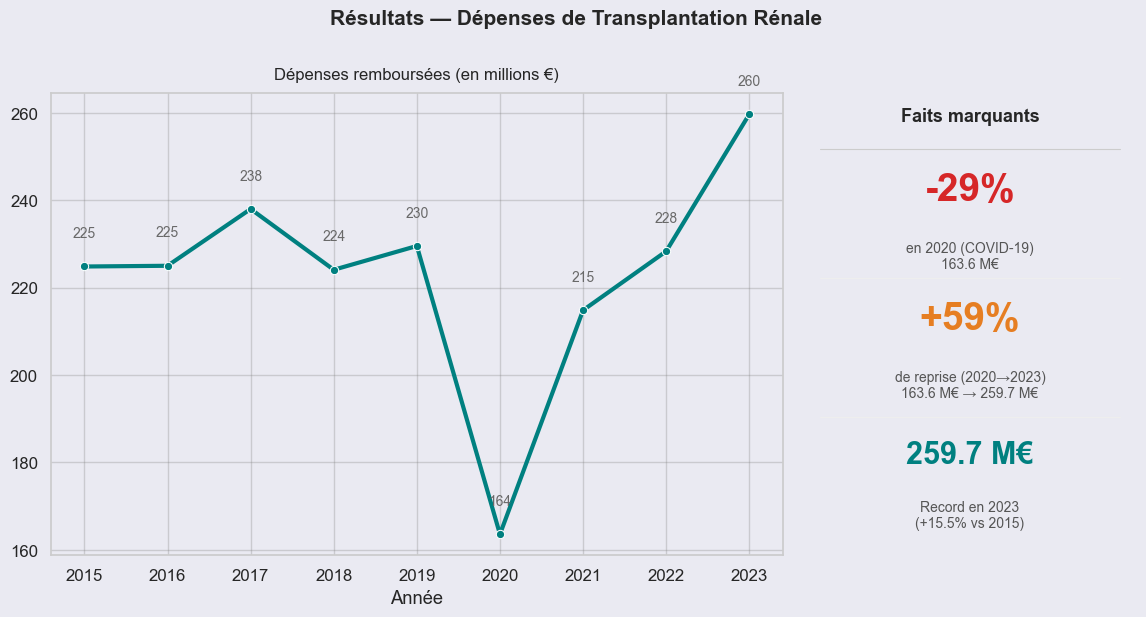

In [5]:
# ── Préparation données ──────────────────────────────────────────────────────
dep_annuel = (
    dep
    .group_by("annee")
    .agg(pl.col("montant").sum().alias("montant_total"))
    .with_columns((pl.col("montant_total") / 1_000_000).alias("montant_M€"))
    .sort("annee")
)
df_plot = dep_annuel.to_pandas()

# ── Calcul des faits marquants ────────────────────────────────────────────────
def v(year):
    return df_plot.loc[df_plot["annee"] == year, "montant_M€"].values[0]

v2015, v2019, v2020, v2023 = v(2015), v(2019), v(2020), v(2023)
chute_covid = (v2020 - v2019) / v2019 * 100   # chute 2019 → 2020
reprise     = (v2023 - v2020) / v2020 * 100   # reprise 2020 → 2023
evol_totale = (v2023 - v2015) / v2015 * 100   # évolution 2015 → 2023

print(f"Chute COVID  (2019→2020) : {chute_covid:+.1f}%  ({v2020:.1f} M€)")
print(f"Reprise      (2020→2023) : {reprise:+.1f}%")
print(f"Évol. totale (2015→2023) : {evol_totale:+.1f}%  ({v2023:.1f} M€)")

# ── Figure : graphe (gauche) + panneau faits marquants (droite) ───────────────
fig = plt.figure(figsize=(14, 6))
fig.patch.set_facecolor("#eaeaf2")

gs      = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.04)
ax      = fig.add_subplot(gs[0])
ax_info = fig.add_subplot(gs[1])

ax.set_facecolor("#eaeaf2")

# Ligne principale
sns.lineplot(data=df_plot, x="annee", y="montant_M€",
             marker="o", linewidth=3, color="#008080", ax=ax)

# Annotations valeurs au-dessus de chaque point
for x, y in zip(df_plot["annee"], df_plot["montant_M€"]):
    ax.text(x, y + 6, f"{int(round(y))}",
            ha="center", va="bottom", fontsize=10, color="dimgray")

ax.set_title("Dépenses remboursées (en millions €)", fontsize=12, pad=10)
ax.set_xlabel("Année")
ax.set_ylabel("")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x)}"))
ax.grid(True, which="major", color="gray", alpha=0.3)
ax.set_xticks(sorted(df_plot["annee"].unique()))

# ── Panneau faits marquants ───────────────────────────────────────────────────
ax_info.set_facecolor("white")
ax_info.axis("off")

T = ax_info.transAxes   # raccourci

ax_info.text(0.5, 0.97, "Faits marquants", ha="center", va="top",
             fontsize=13, fontweight="bold", transform=T)

ax_info.plot([0.05, 0.95], [0.88, 0.88], color="#cccccc",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 1 — chute COVID (rouge)
ax_info.text(0.5, 0.83, f"{chute_covid:+.0f}%", ha="center", va="top",
             fontsize=28, fontweight="bold", color="#D62728", transform=T)
ax_info.text(0.5, 0.68, f"en 2020 (COVID-19)\n{v2020:.1f} M€",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

ax_info.plot([0.05, 0.95], [0.60, 0.60], color="#eeeeee",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 2 — reprise (orange)
ax_info.text(0.5, 0.55, f"{reprise:+.0f}%", ha="center", va="top",
             fontsize=28, fontweight="bold", color="#E67E22", transform=T)
ax_info.text(0.5, 0.40, f"de reprise (2020→2023)\n{v2020:.1f} M€ → {v2023:.1f} M€",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

ax_info.plot([0.05, 0.95], [0.30, 0.30], color="#eeeeee",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 3 — record 2023 (teal)
ax_info.text(0.5, 0.25, f"{v2023:.1f} M€", ha="center", va="top",
             fontsize=22, fontweight="bold", color="#008080", transform=T)
ax_info.text(0.5, 0.12, f"Record en 2023\n({evol_totale:+.1f}% vs 2015)",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

plt.suptitle("Résultats — Dépenses de Transplantation Rénale",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../output/fig_depenses_faits_marquants.png", dpi=150, bbox_inches="tight")
plt.show()

Les dépenses remboursées pour la transplantation rénale ont globalement progressé de +15,5 % entre 2015 et 2023, passant de 225 M€ à 259,7 M€, ce qui en fait une année record. Cette tendance haussière a été brutalement interrompue en 2020 par la crise COVID-19, avec une chute de –29 % par rapport à 2019 (de 230 M€ à 163,6 M€) : la pandémie a entraîné un report massif d'actes chirurgicaux programmés. À partir de 2021, une forte reprise de +59 % s'est amorcée jusqu'en 2023, témoignant d'un effet de rattrapage et d'une reprise soutenue de l'activité de transplantation.

---
## 4. Prévalence du diabète parmi les transplantés rénaux

### 4.1 Nettoyage

In [6]:
raw_comorb.glimpse()

Rows: 40221
Columns: 16
$ annee               <str> '2021', '2021', '2021', '2021', '2021', '2021', '2021', '2021', '2021', '2021'
$ patho_niv1          <str> "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes"
$ patho_niv2          <str> "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affections de longue durée (dont 31 et 32) pour d'autres causes", "Affection

In [7]:
comorb = (
    raw_comorb
    .with_columns([
        pl.col("annee").cast(pl.Int32),
        pl.col("Proportion_comorb").cast(pl.Float64, strict=False),
    ])
    # Filtre sur l'insuffisance rénale chronique terminale
    .filter(pl.col("patho_niv1") == "Insuffisance rénale chronique terminale")
    # Filtre sur la transplantation rénale
    .filter(pl.col("patho_niv2") == "Transplantation rénale")
    # Filtre transplantation rénale uniquement
    .filter(pl.col("patho_niv3")== "Transplantation rénale")
    .filter(pl.col("libelle_comorbidite")== "Diabète")
    # Tri par année et montant
    .sort(["annee"])
)

print(f"Lignes après filtre : {comorb.shape[0]}")
print(f"Années             : {sorted(comorb['annee'].unique().to_list())}")
comorb

Lignes après filtre : 9
Années             : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


annee,patho_niv1,patho_niv2,patho_niv3,top,comorbidite,libelle_comorbidite,region,dept,Ncomorb,Ntop,Proportion_comorb,patho_niv1_comorb,patho_niv2_comorb,patho_niv3_comorb,Niveau prioritaire
i32,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str
2015,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""960""","""3260""",0.292982,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2016,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""950""","""3330""",0.284856,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2017,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""1140""","""3570""",0.318958,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2018,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""1060""","""3330""",0.317102,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2019,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""1160""","""3470""",0.334199,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2020,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""770""","""2510""",0.306342,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2021,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""980""","""3050""",0.321873,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2022,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""1090""","""3180""",0.343593,"""Diabète""","""Diabète""","""Diabète""","""2,3"""
2023,"""Insuffisance rénale chronique terminale""","""Transplantation rénale""","""Transplantation rénale""","""IRT_TRE_AIG""","""DIA_CAT_CAT""","""Diabète""","""99""","""999""","""1130""","""3360""",0.336902,"""Diabète""","""Diabète""","""Diabète""","""2,3"""


### 4.2 Figure — Évolution de la prévalence du diabète

Hausse globale  (2015→2023) : +4.4 pp  (29.3% → 33.7%)
Pic             (2022)      : 34.4%
Creux COVID     (2020)      : 30.6%


C:\Users\Abdo\AppData\Local\Temp\ipykernel_26652\766938430.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


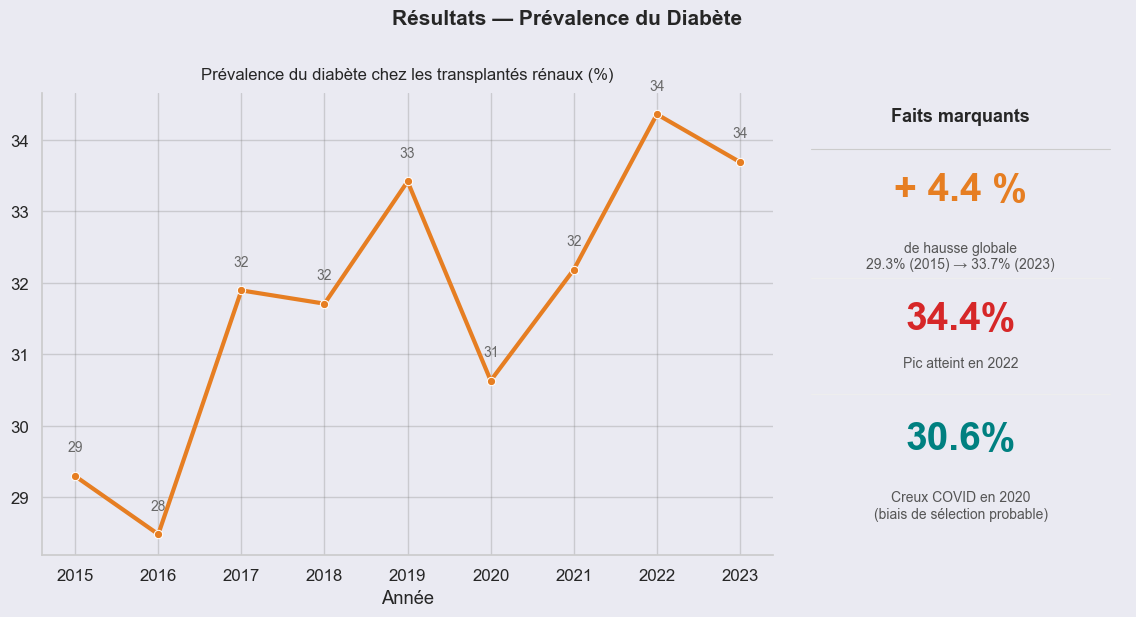

In [8]:
# ── Préparation données ──────────────────────────────────────────────────────
df_plot = comorb.select(["annee", "Proportion_comorb"]).to_pandas()

# ── Calcul des faits marquants ────────────────────────────────────────────────
def p(year):
    return df_plot.loc[df_plot["annee"] == year, "Proportion_comorb"].values[0] * 100

p2015 = p(2015)
p2020 = p(2020)
p2022 = p(2022)
p2023 = p(2023)
pic   = df_plot["Proportion_comorb"].max() * 100
hausse_globale = p2023 - p2015

print(f"Hausse globale  (2015→2023) : +{hausse_globale:.1f} pp  ({p2015:.1f}% → {p2023:.1f}%)")
print(f"Pic             (2022)      : {pic:.1f}%")
print(f"Creux COVID     (2020)      : {p2020:.1f}%")

# ── Figure : graphe (gauche) + panneau faits marquants (droite) ───────────────
fig = plt.figure(figsize=(14, 6))
fig.patch.set_facecolor("#eaeaf2")

gs      = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.04)
ax      = fig.add_subplot(gs[0])
ax_info = fig.add_subplot(gs[1])

ax.set_facecolor("#eaeaf2")

# Ligne principale
sns.lineplot(data=df_plot, x="annee", y="Proportion_comorb",
             marker="o", linewidth=3, color="#E67E22", ax=ax)

# Annotations valeurs (entiers %) au-dessus de chaque point
for x, y in zip(df_plot["annee"], df_plot["Proportion_comorb"]):
    ax.text(x, y + 0.003, f"{int(round(y * 100))}",
            ha="center", va="bottom", fontsize=10, color="dimgray")

ax.set_title("Prévalence du diabète chez les transplantés rénaux (%)",
             fontsize=12, pad=10)
ax.set_xlabel("Année")
ax.set_ylabel("")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}"))
ax.grid(True, which="major", color="gray", alpha=0.3)
ax.set_xticks(sorted(df_plot["annee"].unique()))
sns.despine(ax=ax)

# ── Panneau faits marquants ───────────────────────────────────────────────────
ax_info.set_facecolor("white")
ax_info.axis("off")

T = ax_info.transAxes   # raccourci

ax_info.text(0.5, 0.97, "Faits marquants", ha="center", va="top",
             fontsize=13, fontweight="bold", transform=T)

ax_info.plot([0.05, 0.95], [0.88, 0.88], color="#cccccc",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 1 — hausse globale (orange)
ax_info.text(0.5, 0.83, f"+ {hausse_globale:.1f} %", ha="center", va="top",
             fontsize=28, fontweight="bold", color="#E67E22", transform=T)
ax_info.text(0.5, 0.68, f"de hausse globale\n{p2015:.1f}% (2015) → {p2023:.1f}% (2023)",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

ax_info.plot([0.05, 0.95], [0.60, 0.60], color="#eeeeee",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 2 — pic 2022 (rouge)
ax_info.text(0.5, 0.55, f"{pic:.1f}%", ha="center", va="top",
             fontsize=28, fontweight="bold", color="#D62728", transform=T)
ax_info.text(0.5, 0.43, "Pic atteint en 2022",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

ax_info.plot([0.05, 0.95], [0.35, 0.35], color="#eeeeee",
             linewidth=0.8, transform=T, clip_on=False)

# Fait 3 — creux COVID (teal)
ax_info.text(0.5, 0.29, f"{p2020:.1f}%", ha="center", va="top",
             fontsize=28, fontweight="bold", color="#008080", transform=T)
ax_info.text(0.5, 0.14, "Creux COVID en 2020\n(biais de sélection probable)",
             ha="center", va="top", fontsize=10, color="#555555", transform=T)

plt.suptitle("Résultats — Prévalence du Diabète",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../output/fig_diabete_faits_marquants.png", dpi=150, bbox_inches="tight")
plt.show()

La prévalence du diabète chez les patients transplantés rénaux a augmenté de +4,4 points entre 2015 (29,3 %) et 2023 (33,7 %), avec un pic à 34,4 % en 2022. Cette tendance est globalement croissante sur la période, malgré quelques fluctuations annuelles. Le creux observé en 2020 (30,6 %) est vraisemblablement un artefact lié à la COVID-19, le dépistage et le suivi des comorbidités ayant été perturbés cette année-là, sous-estimant probablement la prévalence réelle.

---

## 5. Merge 

On construit un tableau de synthèse croisant les deux fichiers sur l'année. Ce tableau réunit les six indicateurs principaux : nombre de transplantés, dépenses totales, coût moyen par patient, nombre de transplantés diabétiques et prévalence du diabète. On calcule également les variations relatives entre 2015 et 2023 pour chacun de ces indicateurs, afin de donner une première lecture de l'amplitude des évolutions sur la période. Ces chiffres serviront de base à l'interprétation développée en section 8.

In [9]:
# ── Tableau de synthèse (join sur l'année) ────────────────────────────────────
summary = (
    dep
    .with_columns([
        pl.col("Ntop").cast(pl.Int32, strict=False),
        pl.col("montant_moy").cast(pl.Float64, strict=False),
    ])
    .join(
        comorb
        .with_columns(pl.col("Ncomorb").cast(pl.Int32, strict=False))
        .select(["annee", "Ncomorb", "Proportion_comorb"]),
        on="annee",
        how="left",
    )
    .select([
        pl.col("annee").alias("Année"),
        pl.col("Ntop").alias("Nb transplantés"),

        # conversion en millions
        (pl.col("montant") / 1_000_000)
        .round(1)
        .alias("Dépenses totales (M€)"),

        pl.col("montant_moy").alias("Coût moyen / patient (€)"),
        pl.col("Ncomorb").alias("Nb diabétiques"),
        (pl.col("Proportion_comorb") * 100).round(1).alias("Prévalence diabète (%)"),
    ])
    .sort("Année")
)

summary

Année,Nb transplantés,Dépenses totales (M€),Coût moyen / patient (€),Nb diabétiques,Prévalence diabète (%)
i32,i32,f64,f64,i32,f64
2015,3260,224.8,68905.0,960,29.3
2016,3330,225.0,67609.0,950,28.5
2017,3570,238.0,66648.0,1140,31.9
2018,3330,224.1,67353.0,1060,31.7
2019,3470,229.5,66243.0,1160,33.4
2020,2510,163.6,65244.0,770,30.6
2021,3050,214.8,70342.0,980,32.2
2022,3180,228.3,71708.0,1090,34.4
2023,3360,259.7,77216.0,1130,33.7


In [10]:
# ── Variations 2015 → 2023 ────────────────────────────────────────────────────
def var_pct(df: pl.DataFrame, col: str, a0: int = 2015, a1: int = 2023) -> float:
    v0 = df.filter(pl.col("annee") == a0)[col][0]
    v1 = df.filter(pl.col("annee") == a1)[col][0]
    return (v1 / v0 - 1) * 100

dep_num = dep.with_columns([
    pl.col("Ntop").cast(pl.Float64, strict=False),
    pl.col("montant_moy").cast(pl.Float64, strict=False),
])
comorb_num = comorb.with_columns(
    pl.col("Ncomorb").cast(pl.Float64, strict=False),
)

delta_dep  = var_pct(dep_num,    "montant")
delta_ntop = var_pct(dep_num,    "Ntop")
delta_moy  = var_pct(dep_num,    "montant_moy")
delta_prev = var_pct(comorb_num, "Proportion_comorb")

print("Variations 2015 → 2023 :")
print(f"  Dépenses totales       : {delta_dep:+.1f}%")
print(f"  Nb de transplantés     : {delta_ntop:+.1f}%")
print(f"  Coût moyen par patient : {delta_moy:+.1f}%")
print(f"  Prévalence du diabète  : {delta_prev:+.1f}%")

Variations 2015 → 2023 :
  Dépenses totales       : +15.5%
  Nb de transplantés     : +3.1%
  Coût moyen par patient : +12.1%
  Prévalence du diabète  : +15.0%


### Figure 1 — Variations 2015 → 2023 (barres groupées)

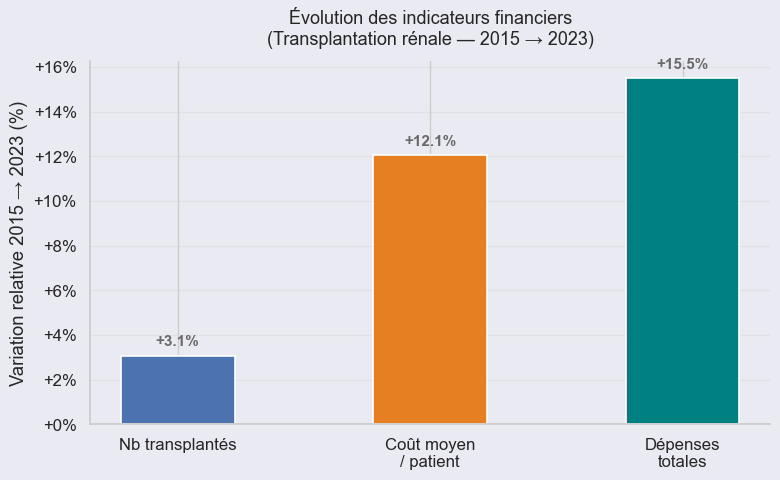

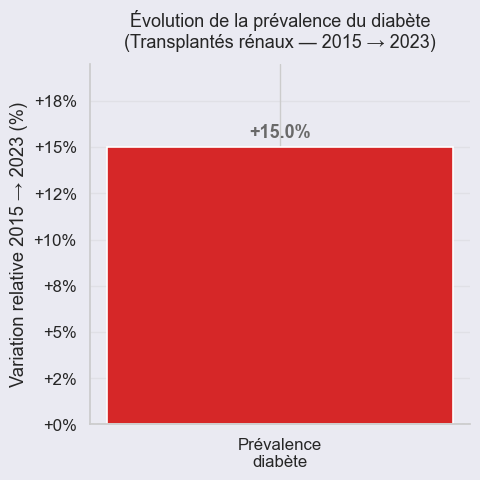

In [11]:
# ── Graphique A — Indicateurs financiers ─────────────────────────────────────
labels_fin  = ["Nb transplantés", "Coût moyen\n/ patient", "Dépenses\ntotales"]
valeurs_fin = [delta_ntop, delta_moy, delta_dep]
couleurs_fin = ["#4C72B0", "#E67E22", "#008080"]

df_fin = pl.DataFrame({
    "indicateur": labels_fin,
    "variation":  valeurs_fin,
    "couleur":    couleurs_fin,
}).to_pandas()

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor("#eaeaf2")
ax.set_facecolor("#eaeaf2")

bars = ax.bar(df_fin["indicateur"], df_fin["variation"],
              color=df_fin["couleur"], width=0.45, edgecolor="white", linewidth=1.2)

for bar, val in zip(bars, valeurs_fin):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.3,
            f"{val:+.1f}%", ha="center", va="bottom",
            fontsize=11, fontweight="bold", color="dimgray")

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Variation relative 2015 → 2023 (%)")
ax.set_title("Évolution des indicateurs financiers\n(Transplantation rénale — 2015 → 2023)",
             fontsize=13, pad=12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:+.0f}%"))
ax.grid(axis="y", alpha=0.3)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("../output/fig_variations_financiers.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Graphique B — Prévalence du diabète ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("#eaeaf2")
ax.set_facecolor("#eaeaf2")

bar = ax.bar(["Prévalence\ndiabète"], [delta_prev],
             color="#D62728", width=0.35, edgecolor="white", linewidth=1.2)

ax.text(0, delta_prev + 0.3, f"{delta_prev:+.1f}%",
        ha="center", va="bottom", fontsize=13, fontweight="bold", color="dimgray")

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Variation relative 2015 → 2023 (%)")
ax.set_title("Évolution de la prévalence du diabète\n(Transplantés rénaux — 2015 → 2023)",
             fontsize=13, pad=12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:+.0f}%"))
ax.set_ylim(0, delta_prev * 1.3)
ax.grid(axis="y", alpha=0.3)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("../output/fig_variation_diabete.png", dpi=150, bbox_inches="tight")
plt.show()

### Évolution des dépenses : une hausse portée par le coût unitaire 
Interpretation : Le nombre de transplantés n'a augmenté que de +3,1 % sur la période, mais les dépenses totales ont bondi de +15,5 %. Cela signifie que la hausse des dépenses n'est pas portée par le volume de patients transplantés car elle reste globalement stable entre 3 180 et 3 570 patients par an sur la période hors-COVID, mais principalement par la hausse du coût par patient (+12,1 %) — les actes ou les traitements associés à chaque greffe coûtent de plus en plus cher à l'Assurance Maladie.


La prévalence du diabète progresse de +15,0 %, soit un rythme comparable à celui des dépenses totales. Ces deux évolutions sont parallèles, mais nos données ne permettent pas d'établir un lien de causalité entre les deux.

L'année 2020 constitue une rupture isolée : les dépenses tombent à 163,6 M€ et les effectifs à 2 510 patients, soit une réduction de près d'un tiers. Cela résulte de la pandémie de COVID-19 qui a entraîné la suspension ou le report de nombreuses greffes programmées, par réduction des dons d'organes et saturation des réanimations. Cette rupture conjoncturelle a été exclue de la modélisation linéaire pour ne pas biaiser l'estimation de la tendance structurelle.


###  Limites 
* Données administratives : pas d'information clinique détaillée (type de diabète,
HbA1c, stade de néphropathie, survie du greffon).
* Pas de causalité possible : on observe des associations et des tendances
temporelles, non des relations causales.
* Le montant remboursé n'est pas le coût réel total (reste à charge et
complémentaire exclus).
* Les données Data Ameli sont agrégées au niveau national : aucune donnée individuelle n'est disponible, ce qui empêche toute analyse en sous-groupe par âge, sexe, ancienneté de la greffe, type de diabète ou traitement immunosuppresseur. Le top `IRT_TRE_AIG` est par construction limité à la phase aiguë de la transplantation : les patients greffés de longue date, suivis sous d'autres codes ALD, ne sont pas capturés dans ce périmètre. 